Question 1

In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\BISHOP LUBEGA\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
# PROJECT 2: CONCRETE COMPRESSIVE STRENGTH
# Data Exploration, Preparation and Mean Baseline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# 1. LOAD DATASET

df = pd.read_csv("Concrete_Data.csv")

print("FIRST FIVE RECORDS")
print(df.head())

print("\nDATASET SHAPE")
print(df.shape)


# 2. DATA EXPLORATION


print("\nDATA TYPES")
print(df.dtypes)

print("\nDESCRIPTIVE STATISTICS")
print(df.describe().T)

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nDUPLICATE RECORDS")
print(df.duplicated().sum())


# 3. DATA PREPARATION


# Remove exact duplicate records
df = df.drop_duplicates().copy()

# Check missing values again
print("\nMISSING VALUES AFTER CLEANING")
print(df.isnull().sum())

# Save cleaned dataset
df.to_csv("Cleaned_Concrete_Data.csv", index=False)

print("\nCleaned dataset shape:", df.shape)


FIRST FIVE RECORDS
   Cement (kg in a m^3 mixture)  Blast Furnace Slag (kg in a m^3 mixture)  \
0                         540.0                                       0.0   
1                         540.0                                       0.0   
2                         332.5                                     142.5   
3                         332.5                                     142.5   
4                         198.6                                     132.4   

   Fly Ash (kg in a m^3 mixture)  Water (kg in a m^3 mixture)  \
0                            0.0                        162.0   
1                            0.0                        162.0   
2                            0.0                        228.0   
3                            0.0                        228.0   
4                            0.0                        192.0   

   Superplasticizer (kg in a m^3 mixture)  \
0                                     2.5   
1                                    

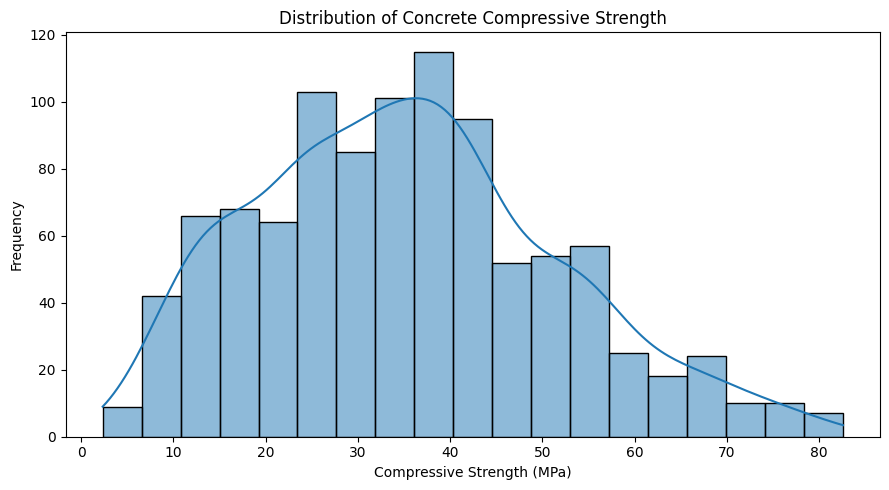

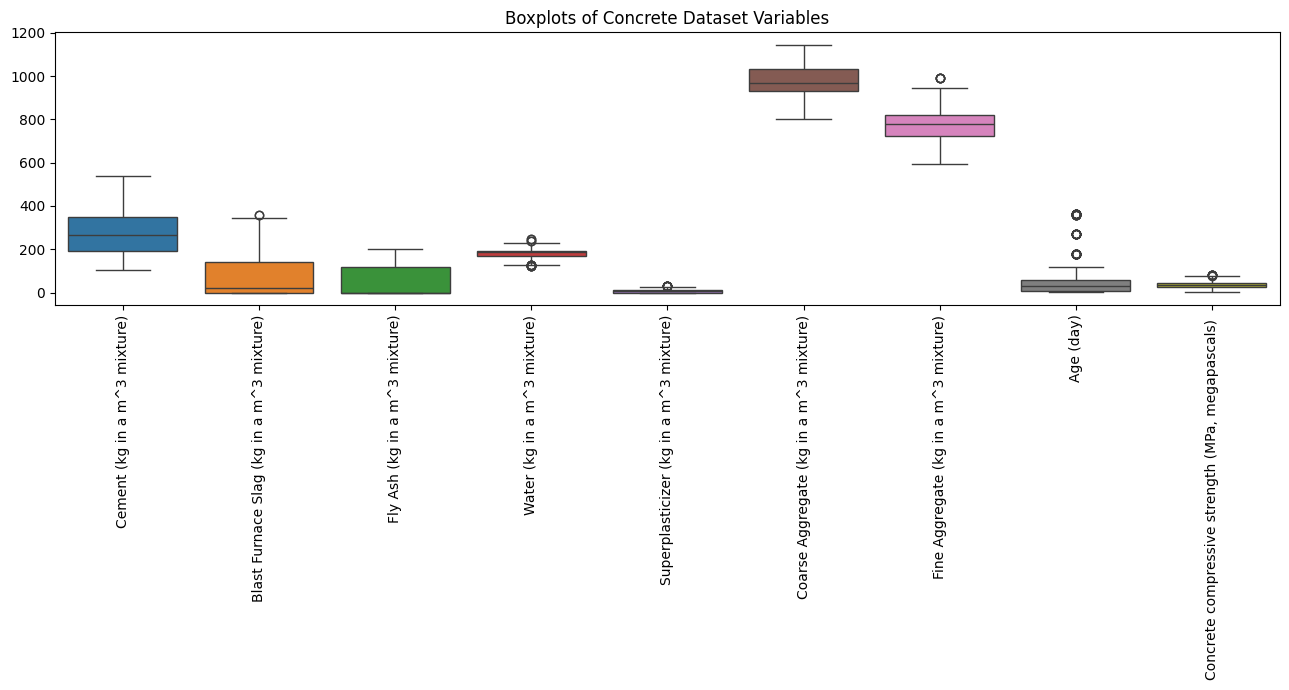

In [4]:
# ------------------------------------------------
# 4. DESCRIPTIVE VISUALISATIONS
# ------------------------------------------------

# Distribution of compressive strength
target = df.columns[-1]

plt.figure(figsize=(9, 5))
sns.histplot(df[target], kde=True)
plt.title("Distribution of Concrete Compressive Strength")
plt.xlabel("Compressive Strength (MPa)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# Boxplots for numerical variables
plt.figure(figsize=(13, 7))
sns.boxplot(data=df)
plt.xticks(rotation=90)
plt.title("Boxplots of Concrete Dataset Variables")
plt.tight_layout()
plt.show()




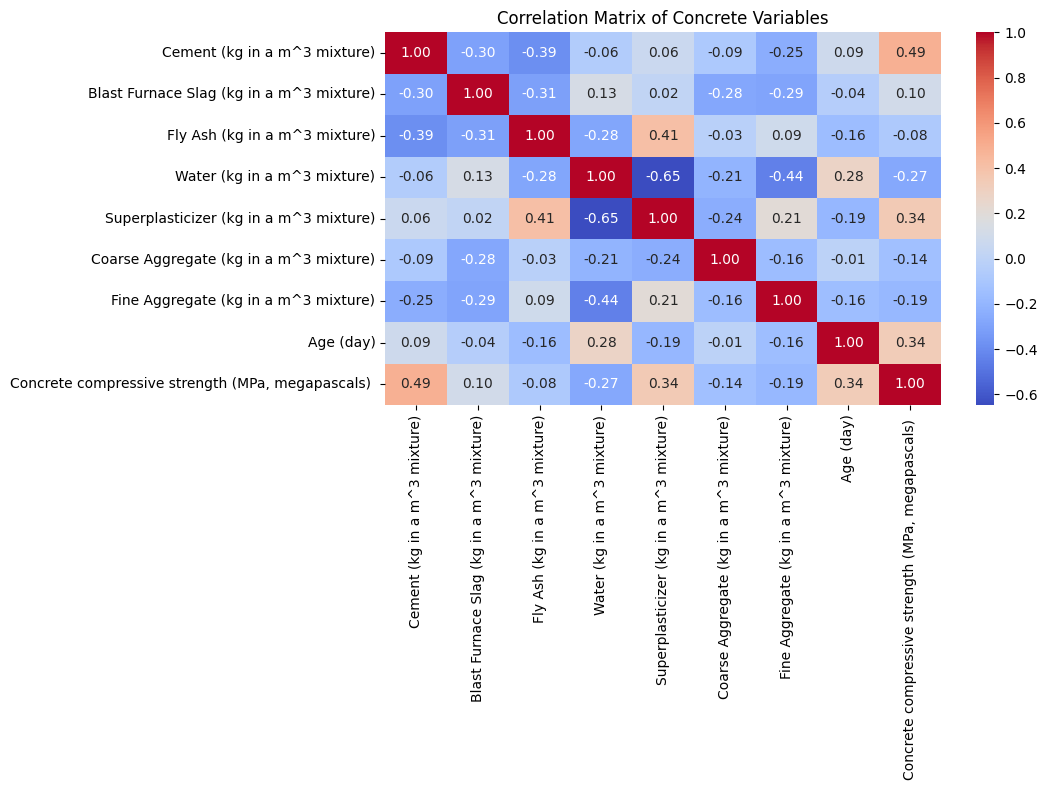

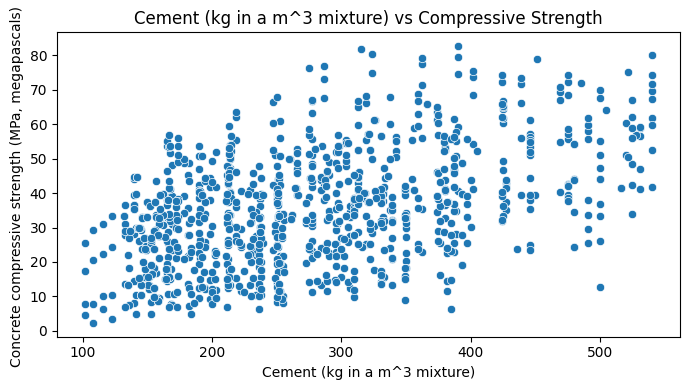

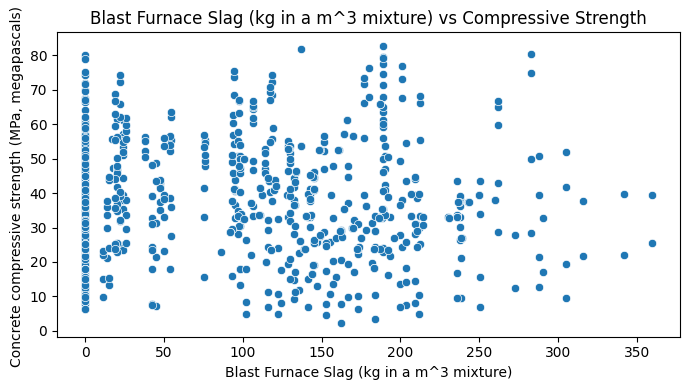

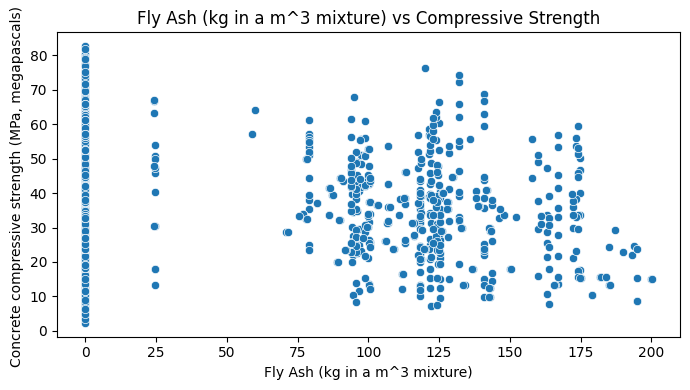

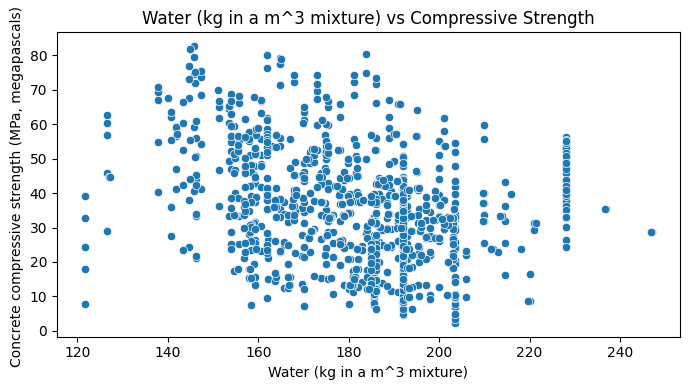

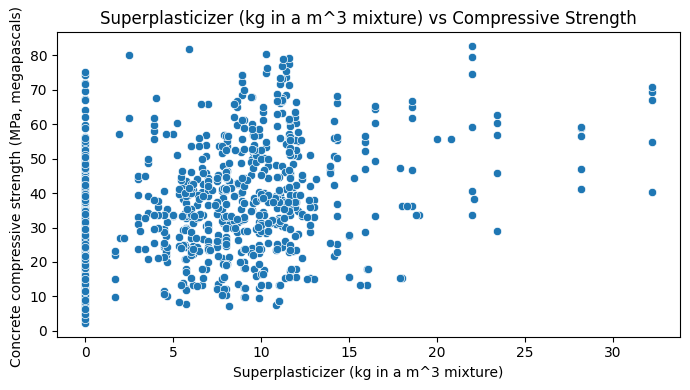

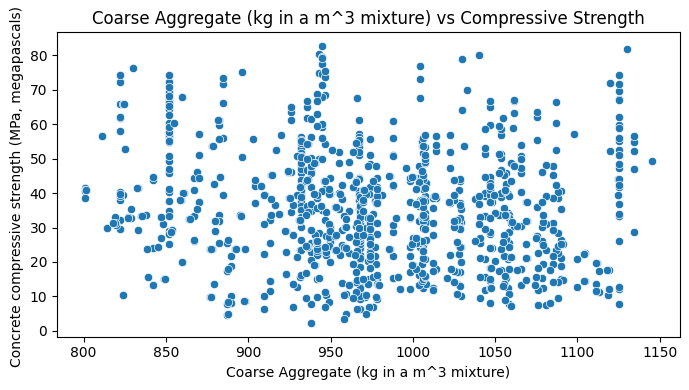

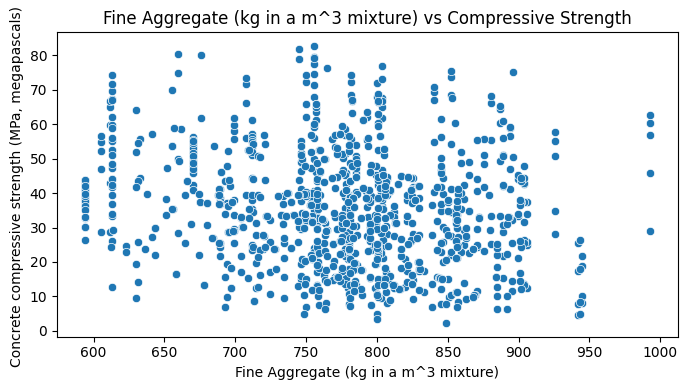

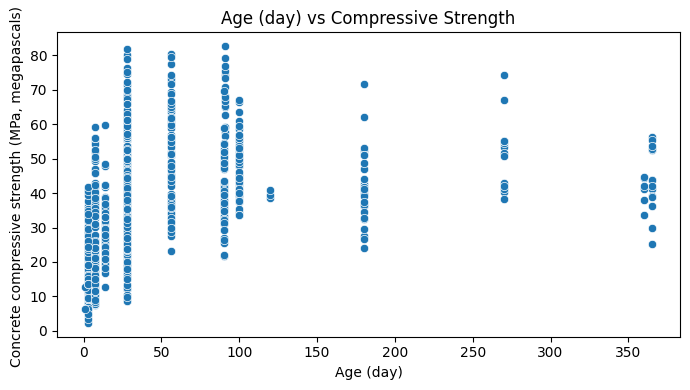

In [5]:
# Correlation heatmap
plt.figure(figsize=(11, 8))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Matrix of Concrete Variables")
plt.tight_layout()
plt.show()

# Scatter plots against target
features = df.columns[:-1]

for feature in features:
    plt.figure(figsize=(7, 4))
    sns.scatterplot(data=df, x=feature, y=target)
    plt.title(f"{feature} vs Compressive Strength")
    plt.tight_layout()
    plt.show()

In [7]:
# 5. DEFINE INPUTS AND TARGET
# ------------------------------------------------

X = df.drop(columns=[target])
y = df[target]

print("\nINPUT VARIABLES")
print(X.head(5))

print("\nTARGET VARIABLE")
print(y.head(5))



INPUT VARIABLES
   Cement (kg in a m^3 mixture)  Blast Furnace Slag (kg in a m^3 mixture)  \
0                         540.0                                       0.0   
1                         540.0                                       0.0   
2                         332.5                                     142.5   
3                         332.5                                     142.5   
4                         198.6                                     132.4   

   Fly Ash (kg in a m^3 mixture)  Water (kg in a m^3 mixture)  \
0                            0.0                        162.0   
1                            0.0                        162.0   
2                            0.0                        228.0   
3                            0.0                        228.0   
4                            0.0                        192.0   

   Superplasticizer (kg in a m^3 mixture)  \
0                                     2.5   
1                                     2

In [9]:

# TRAIN-TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTRAINING OBSERVATIONS:", len(X_train))
print("TESTING OBSERVATIONS:", len(X_test))


#  MEAN-PREDICTION BASELINE


baseline = DummyRegressor(strategy="mean")

# Train baseline
baseline.fit(X_train, y_train)

# Generate predictions
y_pred = baseline.predict(X_test)

print("\nMEAN BASELINE PREDICTION")
print("Training mean:", y_train.mean())


TRAINING OBSERVATIONS: 804
TESTING OBSERVATIONS: 201

MEAN BASELINE PREDICTION
Training mean: 35.06680914403518


In [10]:
# MODEL EVALUATION
# ------------------------------------------------

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("\nBASELINE PERFORMANCE")
print("-----------------------------")
print(f"MAE:  {mae:.4f} MPa")
print(f"RMSE: {rmse:.4f} MPa")
print(f"R2:   {r2:.4f}")



BASELINE PERFORMANCE
-----------------------------
MAE:  13.9723 MPa
RMSE: 17.2965 MPa
R2:   -0.0028


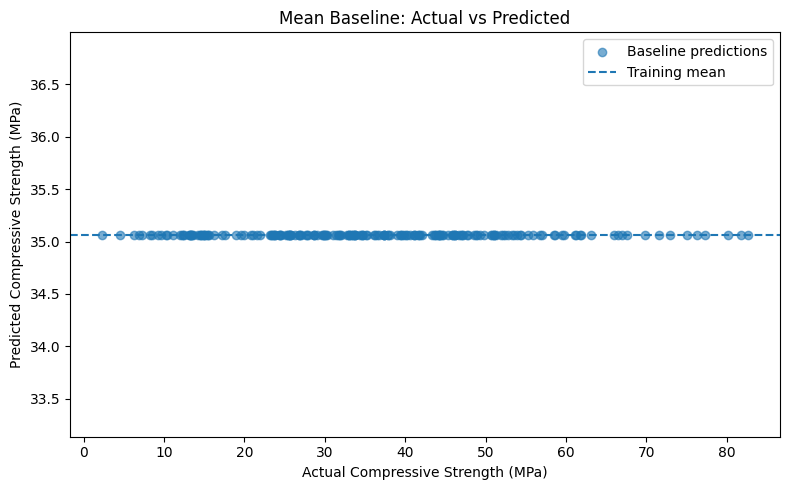


Analysis completed successfully!


In [11]:

# ACTUAL VS PREDICTED VISUALISATION

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.6,
    label="Baseline predictions"
)

plt.axhline(
    y_train.mean(),
    linestyle="--",
    label="Training mean"
)

plt.xlabel("Actual Compressive Strength (MPa)")
plt.ylabel("Predicted Compressive Strength (MPa)")
plt.title("Mean Baseline: Actual vs Predicted")
plt.legend()
plt.tight_layout()
plt.show()


# SAVE BASELINE RESULTS


results = pd.DataFrame({
    "Actual_Strength": y_test.values,
    "Predicted_Strength": y_pred
})

results.to_csv("Concrete_Baseline_Predictions.csv",
               index=False)

print("\nAnalysis completed successfully!")


The baseline MAE of approximately 13.97 MPa means that the model's predictions differ from the actual compressive strengths by an average absolute amount of about 13.97 MPa.

The RMSE of approximately 17.30 MPa indicates the magnitude of prediction errors, with larger errors receiving greater weight.

The (R^2) value of -0.0028 indicates that the mean baseline performs slightly worse than predicting the mean of the test observations. This is expected because the model does not consider the individual mixture characteristics or curing age.

The baseline is therefore not expected to provide accurate predictions. Its main purpose is to establish a minimum benchmark that more advanced predictive models should improve upon.

Question2 

In [7]:
# ==========================================================
# PROJECT 2: CONCRETE STRENGTH PREDICTION
# LINEAR VS NONLINEAR MODELS AND RESIDUAL ANALYSIS
# ==========================================================

#  Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)
from sklearn.dummy import DummyRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

#  Load dataset
df = pd.read_csv("Concrete_Data.csv")

# Clean column names
df.columns = df.columns.str.strip()

target = "Concrete compressive strength (MPa, megapascals)"

#  Remove duplicates
df = df.drop_duplicates()

#  Separate predictors and target
X = df.drop(columns=[target])
y = df[target]

#  Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

#  Define models
models = {
    "Mean Baseline": DummyRegressor(strategy="mean"),

    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=500,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=300,
        learning_rate=0.03,
        max_depth=2,
        loss="huber",
        random_state=42
    )
}

#  Train and evaluate models
results = []
predictions = {}
fitted_models = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    fitted_models[name] = model

    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

#  Display comparison
comparison = pd.DataFrame(results)

print("\nMODEL PERFORMANCE COMPARISON")
print(comparison.round(4))

Training observations: 804
Testing observations: 201

MODEL PERFORMANCE COMPARISON
               Model      MAE       MSE     RMSE      R2
0      Mean Baseline  13.9723  299.1696  17.2965 -0.0028
1  Linear Regression   8.8960  125.2653  11.1922  0.5801
2      Random Forest   3.4614   26.1385   5.1126  0.9124
3  Gradient Boosting   4.9461   44.5242   6.6726  0.8508


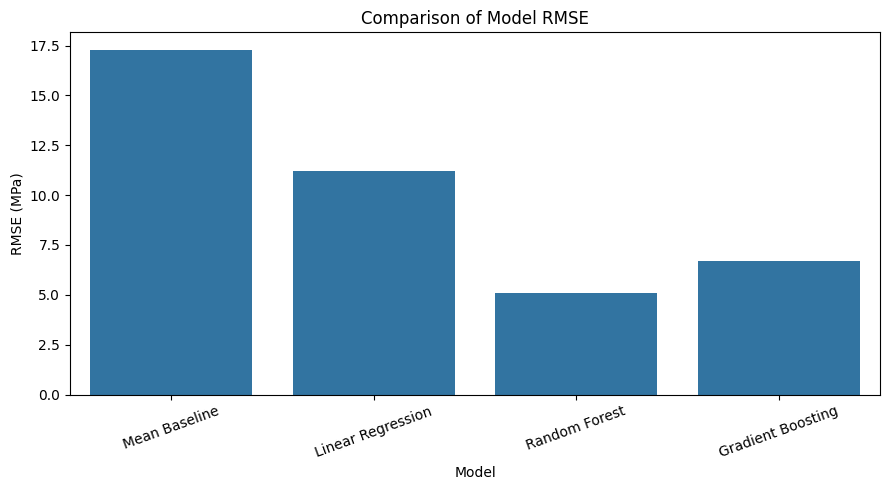

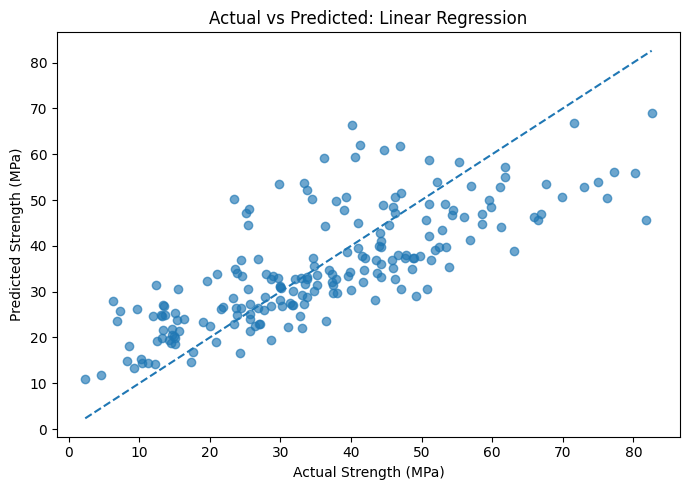

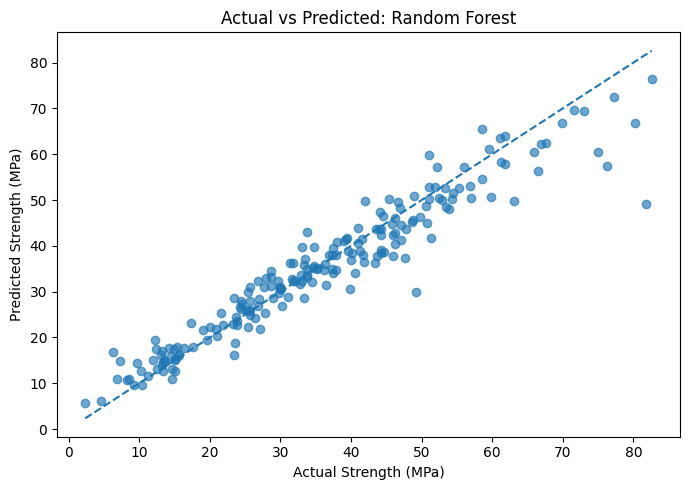

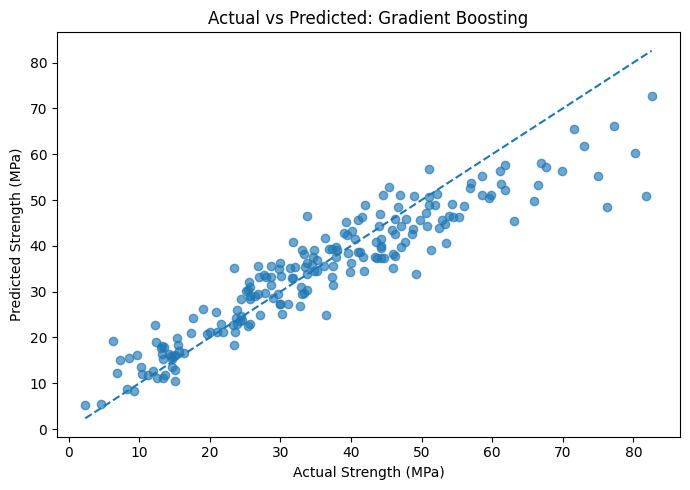

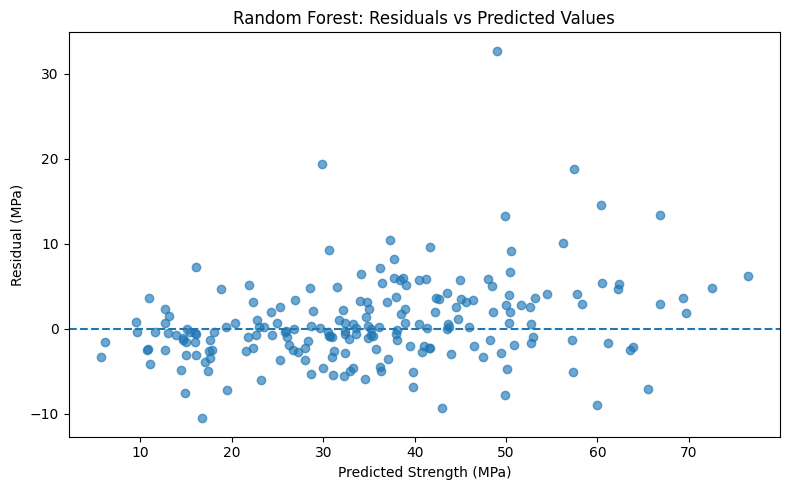

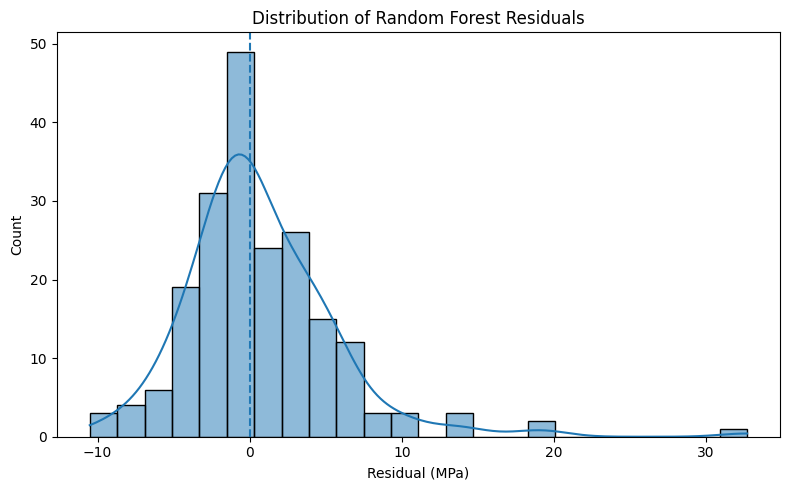

In [5]:
# Plot model comparison
plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison,
    x="Model",
    y="RMSE"
)

plt.title("Comparison of Model RMSE")
plt.ylabel("RMSE (MPa)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

#  Actual vs predicted plots
for name in [
    "Linear Regression",
    "Random Forest",
    "Gradient Boosting"
]:

    y_pred = predictions[name]

    plt.figure(figsize=(7, 5))

    plt.scatter(
        y_test,
        y_pred,
        alpha=0.65
    )

    minimum = min(y_test.min(), y_pred.min())
    maximum = max(y_test.max(), y_pred.max())

    plt.plot(
        [minimum, maximum],
        [minimum, maximum],
        linestyle="--"
    )

    plt.xlabel("Actual Strength (MPa)")
    plt.ylabel("Predicted Strength (MPa)")

    plt.title(f"Actual vs Predicted: {name}")

    plt.tight_layout()
    plt.show()

# Random Forest residual analysis
best_model = fitted_models["Random Forest"]

best_predictions = predictions["Random Forest"]

residuals = y_test - best_predictions

# Residuals vs predicted values
plt.figure(figsize=(8, 5))

plt.scatter(
    best_predictions,
    residuals,
    alpha=0.65
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Strength (MPa)")
plt.ylabel("Residual (MPa)")

plt.title("Random Forest: Residuals vs Predicted Values")

plt.tight_layout()
plt.show()






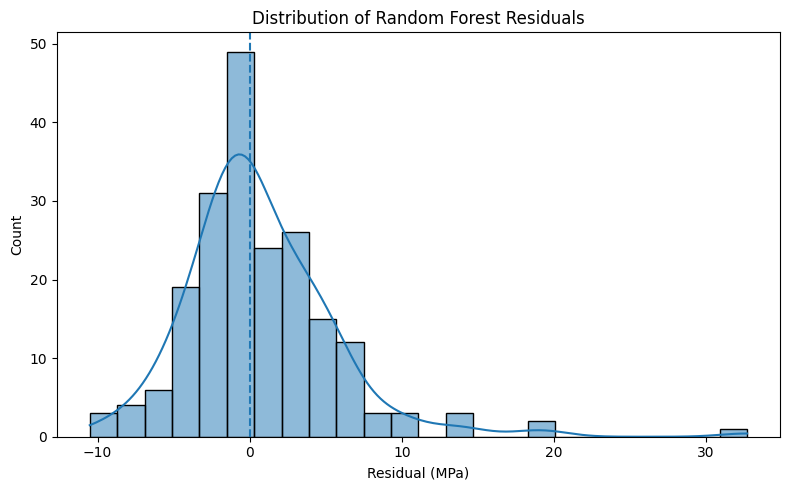

In [6]:
# Residual distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    residuals,
    kde=True
)

plt.axvline(
    0,
    linestyle="--"
)

plt.title("Distribution of Random Forest Residuals")
plt.xlabel("Residual (MPa)")

plt.tight_layout()
plt.show()

In [4]:
#  Create diagnostic dataframe
diagnostics = X_test.copy()

diagnostics["Actual"] = y_test.values

diagnostics["Predicted"] = best_predictions

diagnostics["Residual"] = residuals.values

diagnostics["Absolute_Error"] = np.abs(residuals.values)

#  Residual analysis by actual strength
diagnostics["Strength_Category"] = pd.cut(
    diagnostics["Actual"],
    bins=[0, 20, 40, 60, 100],
    labels=["Below 20", "20-40", "40-60", "Above 60"]
)

strength_analysis = diagnostics.groupby(
    "Strength_Category",
    observed=False
).agg(
    Observations=("Actual", "size"),
    MAE=("Absolute_Error", "mean"),
    RMSE=("Residual", lambda x: np.sqrt(np.mean(x**2))),
    Mean_Residual=("Residual", "mean")
)

print("\nERRORS BY STRENGTH CATEGORY")
print(strength_analysis.round(3))

# Residual analysis by curing age
diagnostics["Age_Category"] = pd.cut(
    diagnostics["Age (day)"],
    bins=[0, 7, 28, 90, 366],
    labels=["1-7 days", "8-28 days",
            "29-90 days", "91-365 days"]
)

age_analysis = diagnostics.groupby(
    "Age_Category",
    observed=False
).agg(
    Observations=("Actual", "size"),
    MAE=("Absolute_Error", "mean"),
    RMSE=("Residual", lambda x: np.sqrt(np.mean(x**2))),
    Mean_Residual=("Residual", "mean")
)

print("\nERRORS BY CURING AGE")
print(age_analysis.round(3))


ERRORS BY STRENGTH CATEGORY
                   Observations    MAE    RMSE  Mean_Residual
Strength_Category                                            
Below 20                     40  2.508   3.370         -2.056
20-40                        81  2.392   3.210         -0.694
40-60                        62  4.074   5.195          2.345
Above 60                     18  8.282  11.284          7.774

ERRORS BY CURING AGE
              Observations    MAE   RMSE  Mean_Residual
Age_Category                                           
1-7 days                56  2.731  3.563         -0.392
8-28 days               89  4.011  6.321          1.003
29-90 days              27  3.513  4.469          0.774
91-365 days             29  3.138  3.930          2.026



TEN LARGEST PREDICTION ERRORS
     Actual  Predicted  Residual  Absolute_Error  Age (day)
381   81.75      49.06     32.69           32.69         28
395   49.25      29.91     19.34           19.34         28
404   76.24      57.44     18.80           18.80         28
828   74.99      60.43     14.55           14.55         28
153   80.20      66.87     13.33           13.33         56
356   63.14      49.84     13.30           13.30         28
763    6.27      16.78    -10.51           10.51          1
355   47.71      37.26     10.45           10.45         14
333   66.42      56.29     10.14           10.14        100
336   51.33      41.67      9.66            9.66         28


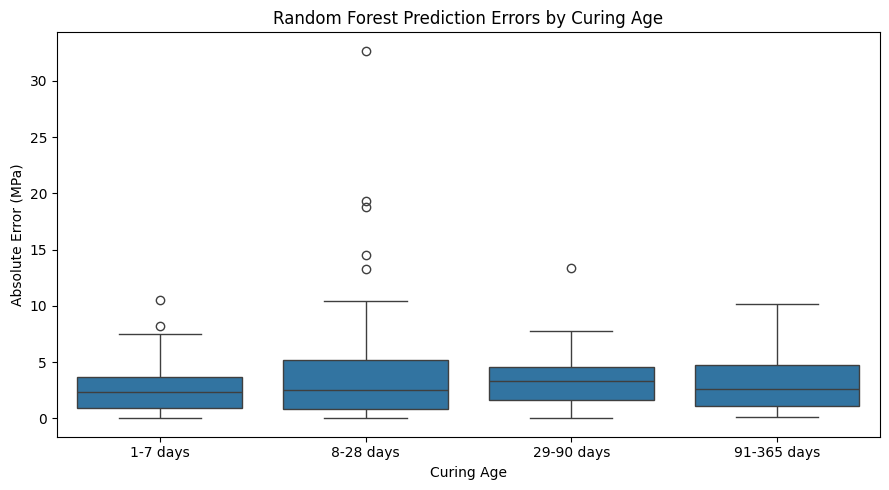

In [3]:
#  Identify largest prediction errors
print("\nTEN LARGEST PREDICTION ERRORS")

largest_errors = diagnostics.sort_values(
    by="Absolute_Error",
    ascending=False
)

print(
    largest_errors[
        ["Actual", "Predicted", "Residual",
         "Absolute_Error", "Age (day)"]
    ].head(10).round(2)
)

#  Plot prediction errors by curing age
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=diagnostics,
    x="Age_Category",
    y="Absolute_Error"
)

plt.title("Random Forest Prediction Errors by Curing Age")

plt.xlabel("Curing Age")

plt.ylabel("Absolute Error (MPa)")

plt.tight_layout()
plt.show()

In [2]:
#  Comparing the training and testing performances
print("\nTRAINING VS TESTING PERFORMANCE")

for name, model in fitted_models.items():

    train_pred = model.predict(X_train)

    test_pred = predictions[name]

    print("\n", name)

    print(
        "Training R2:",
        round(r2_score(y_train, train_pred), 4)
    )

    print(
        "Testing R2:",
        round(r2_score(y_test, test_pred), 4)
    )

    print(
        "Training MAE:",
        round(mean_absolute_error(y_train, train_pred), 4)
    )

    print(
        "Testing MAE:",
        round(mean_absolute_error(y_test, test_pred), 4)
    )

#  Save results
comparison.to_csv(
    "Concrete_Model_Comparison.csv",
    index=False
)

diagnostics.to_csv(
    "Concrete_Residual_Analysis.csv",
    index=True
)

print("\nAnalysis completed successfully.")
print("Model comparison and residual results saved.")


TRAINING VS TESTING PERFORMANCE

 Mean Baseline
Training R2: 0.0
Testing R2: -0.0028
Training MAE: 12.9366
Testing MAE: 13.9723

 Linear Regression
Training R2: 0.6098
Testing R2: 0.5801
Training MAE: 7.9606
Testing MAE: 8.896

 Random Forest
Training R2: 0.9845
Testing R2: 0.9124
Training MAE: 1.3361
Testing MAE: 3.4614

 Gradient Boosting
Training R2: 0.8907
Testing R2: 0.8508
Training MAE: 3.9496
Testing MAE: 4.9461

Analysis completed successfully.
Model comparison and residual results saved.


Conclusion
This stage of the study compared linear and nonlinear regression techniques for predicting concrete compressive strength.

Multiple Linear Regression, Random Forest Regression and Gradient Boosting Regression were developed and evaluated against the mean-prediction baseline using an identical 80:20 training-testing partition.

Random Forest achieved the best overall predictive performance, recording an MAE of 3.46 MPa, RMSE of 5.11 MPa and R² of 0.9124.

Gradient Boosting achieved an R² of 0.8508, while Multiple Linear Regression achieved an R² of 0.5801.

These results provide evidence that nonlinear modelling approaches are more effective than the conventional linear approach for capturing relationships between concrete mixture composition, curing age and compressive strength in the supplied dataset.

Residual analysis further revealed that prediction errors were not uniform across all observations.

The weakest predictions occurred among concrete samples with actual compressive strength above 60 MPa. Random Forest also demonstrated relatively large errors for certain mixtures tested at 28 days.

The findings therefore establish Random Forest as the strongest candidate among the evaluated models, while highlighting the need for further investigation into high-strength concrete predictions and model generalisation.

Question3

In [ ]:
No, because A predictive association between cement content and concrete compressive strength does not necessarily prove what
 will happen in the real world if we deliberately change the cement content. This is because predictive modelling identifies 
 statistical relationships in observed data whereas determining the effects of changing a mixture requires causal evidence.

1. Predictive Association Versus Causation
In the concrete strength dataset, cement content demonstrates a positive correlation with compressive strength 
(approximately (r=0.49), based on the earlier exploratory analysis).

This suggests that concrete mixtures containing higher cement quantities tend to have higher compressive strength 
in the observed dataset. However, correlation does not establish causation.

A predictive model may learn that cement content is associated with strength, but this does not establish that increasing 
cement in an existing mixture will necessarily increase its strength.

2. Why Predictive Association Does Not Prove Causation
There are several reasons why the observed relationship may not represent the actual effect of changing cement content.

a) Confounding variables. Concrete strength depends on several interacting factors, including:
- Water content.
- Water-to-cement ratio.
- Curing age.
- Superplasticizer quantity.
- Aggregate composition.
- Blast furnace slag and fly ash.
For example, mixtures containing higher cement content may also have different water-to-cement ratios. Consequently, 
the observed increase in strength may partly reflect differences in other mixture characteristics.

b) Interactions between ingredients. Concrete ingredients do not operate independently.
 Increasing cement content without adjusting water or other components may produce a different result from increasing cement 
 while maintaining an appropriate water-to-cement ratio. Therefore the effect of cement may depend on the proportions of 
 other ingredients.

c) Differences between observed and experimental conditions

The dataset contains historical experimental observations. These observations describe mixtures that were actually tested.
Changing the cement content of an existing mixture creates a new experimental condition. Its resulting compressive 
strength cannot be established with certainty simply by examining associations in historical data.

d) Model limitations

Even a highly accurate predictive model, such as the Random Forest model developed in this study (R² = 0.9124), does not 
automatically establish causation. The model learns patterns from the available observations. Its predictions may be unreliable 
when applied to mixture combinations that differ substantially from those represented in the training dataset.